# Jupyter Notebook for Principle Component Analysis


In this section we:

- Select a numeric feature set
- Filter out low-minute players
- Standardize features
- Fit PCA and inspect explained variance
- Visualize:
  - Scree plot (variance per component)
  - Cumulative explained variance
  - 2D projection on first two principal components

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import numpy as np
import seaborn as sns


In [21]:
PATH = "../../statsbomb_pipeline/data/processed/player_season_model_dataset.csv"

np.set_printoptions(suppress=True, precision=4)
pd.set_option("display.float_format", "{:.4f}".format)

df = pd.read_csv(PATH)
# Core numeric features for PCA
pca_features = [
    "minutes_played_total",
    "matches_played",
    "xThreat_total",
    "xThreat_pass_total",
    "xThreat_carry_total",
    "xg_total",
    "xThreat_per90",
    "xThreat_pass_per90",
    "xThreat_carry_per90",
]

# Optional: filter out tiny-minute players (keeps things less noisy)
MIN_MINUTES = 900  # tweak if needed
pca_df = df[df["minutes_played_total"] >= MIN_MINUTES].copy()

print("PCA sample size:", pca_df.shape[0])
pca_df[pca_features].describe()



PCA sample size: 324


,minutes_played_total,matches_played,xThreat_total,xThreat_pass_total,xThreat_carry_total,xg_total,xThreat_per90,xThreat_pass_per90,xThreat_carry_per90
count,324.0000,324.0000,324.0000,324.0000,324.0000,324.0000,324.0000,324.0000,324.0000
mean,2098.2514,27.1790,2.4629,2.0804,0.3825,2.6919,0.1026,0.0859,0.0167
std,732.1610,7.1912,1.8133,1.6507,0.5280,3.4041,0.0648,0.0588,0.0246
min,900.0000,10.0000,-0.5540,-0.6918,-1.3078,0.0000,-0.0533,-0.0635,-0.0577
25%,1460.2792,22.0000,1.2295,1.0594,0.0564,0.6428,0.0595,0.0508,0.0024
50%,2044.1750,28.0000,2.0324,1.7303,0.2988,1.5660,0.0924,0.0771,0.0121
75%,2721.4167,33.0000,3.2732,2.6968,0.5848,3.2055,0.1313,0.1093,0.0265
max,3420.8333,38.0000,10.9647,9.3841,2.6907,22.2987,0.3685,0.3111,0.1182


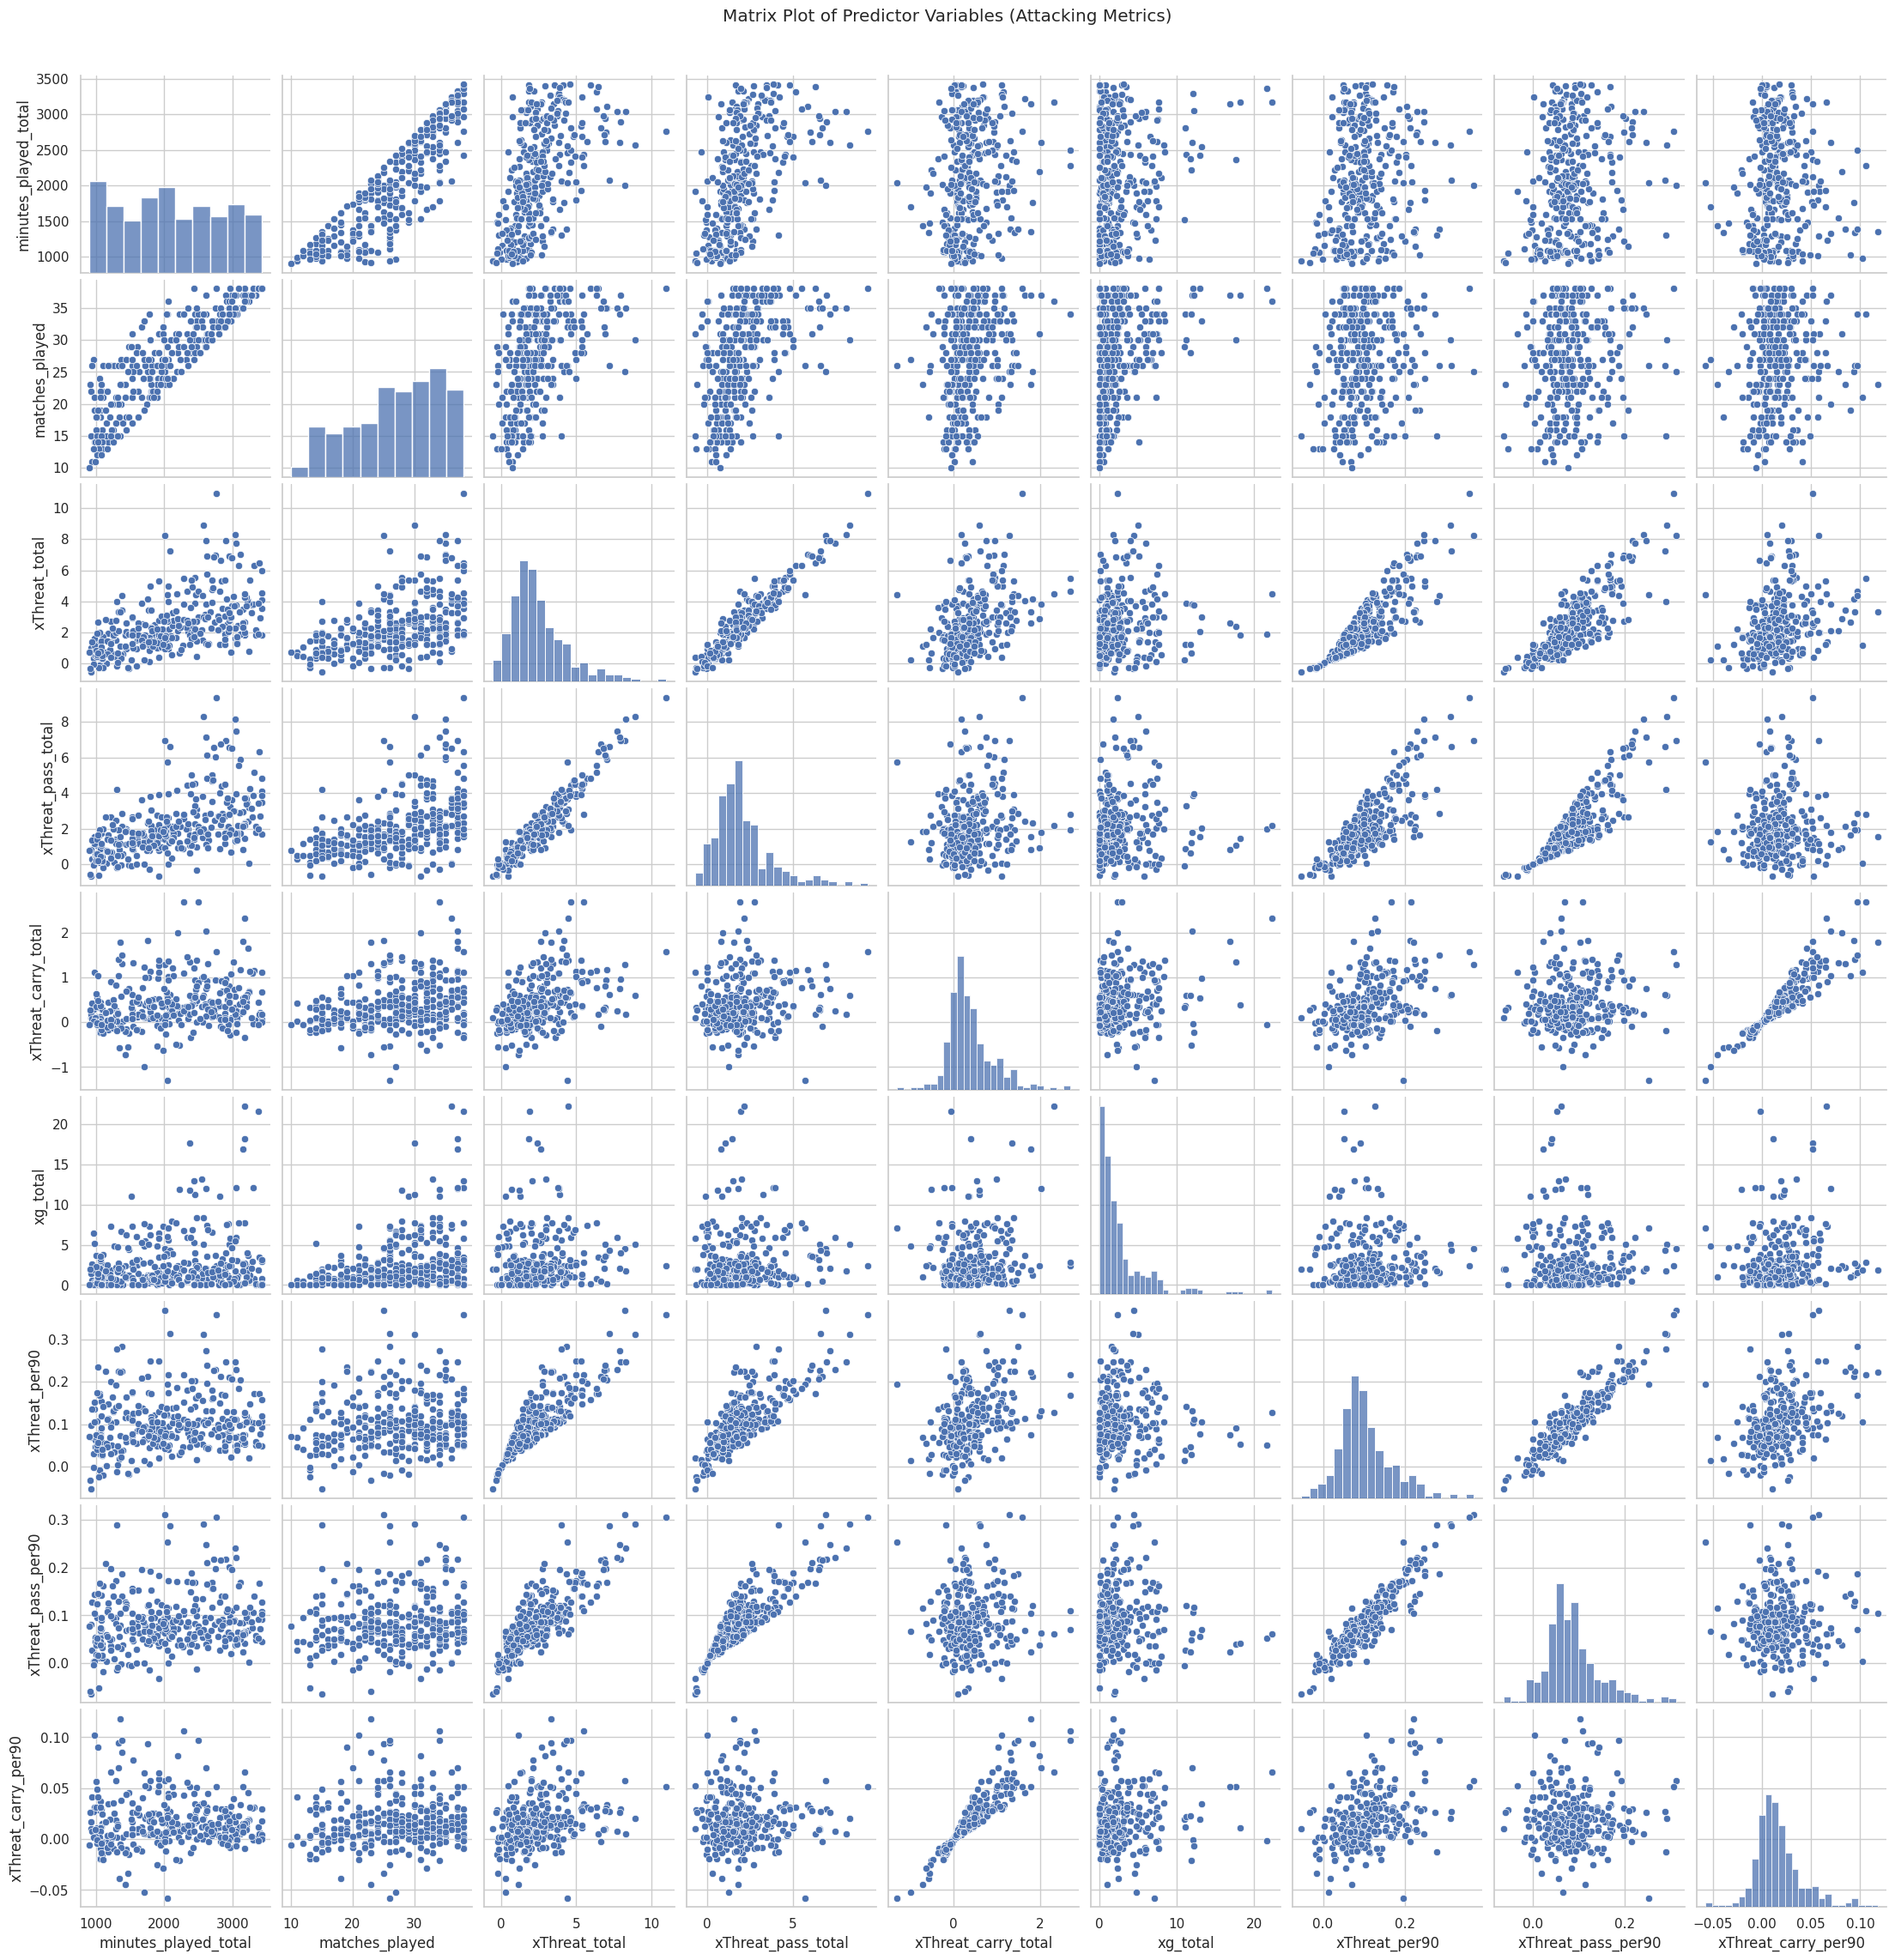

In [5]:
sns.set(style="whitegrid")

pairplot = sns.pairplot(
    pca_df[pca_features],
    diag_kind="hist",
    #corner=True  # only plot lower triangle so it's not overwhelming
)

pairplot.fig.suptitle(
    "Matrix Plot of Predictor Variables (Attacking Metrics)",
    y=1.02
)

plt.show()

In [16]:
X = pca_df[pca_features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()  # keep all components
X_pca = pca.fit_transform(X_scaled)

explained_var = pca.explained_variance_ratio_
explained_var

components = pca.components_ 
components

array([[ 0.2794,  0.2785,  0.4729,  0.4406,  0.2466,  0.102 ,  0.4177,
         0.3851,  0.1805],
       [-0.1539, -0.0645, -0.0658, -0.2667,  0.6075,  0.1898,  0.0326,
        -0.2389,  0.6584],
       [ 0.5296,  0.567 , -0.0525, -0.0679,  0.032 ,  0.3718, -0.3502,
        -0.3451, -0.0981],
       [-0.3061, -0.1437, -0.0373,  0.012 , -0.1656,  0.8933,  0.1071,
         0.1731, -0.1317],
       [-0.3405,  0.6909, -0.3119, -0.2628, -0.2496, -0.1126,  0.2795,
         0.2315,  0.1834],
       [ 0.6196, -0.2834, -0.3831, -0.4077, -0.0411,  0.0512,  0.3216,
         0.3365,  0.043 ],
       [-0.1558,  0.1357, -0.0342, -0.2482,  0.6583, -0.0462, -0.0165,
         0.2453, -0.6313],
       [ 0.    ,  0.    ,  0.5665, -0.5157, -0.165 , -0.    , -0.4429,
         0.4019,  0.1678],
       [ 0.    , -0.    ,  0.449 , -0.4088, -0.1308,  0.    ,  0.5588,
        -0.507 , -0.2117]])

In [22]:
# Eigenvalues and variance breakdown

eigenvalues = pca.explained_variance_              # raw variance for each PC
explained_var = pca.explained_variance_ratio_      # proportion of variance
cumulative_var = np.cumsum(explained_var)

pc_indices = np.arange(1, len(eigenvalues) + 1)

variance_table = pd.DataFrame({
    "PC": pc_indices,
    "Eigenvalue": eigenvalues,
    "Prop_Var": explained_var,
    "Cum_Prop_Var": cumulative_var
})

variance_table["Prop_Var_%"] = variance_table["Prop_Var"] * 100
variance_table["Cum_Prop_Var_%"] = variance_table["Cum_Prop_Var"] * 100

variance_table


,PC,Eigenvalue,Prop_Var,Cum_Prop_Var,Prop_Var_%,Cum_Prop_Var_%
0,1,4.3239,0.4789,0.4789,47.8949,47.8949
1,2,1.8629,0.2063,0.6853,20.6350,68.5299
2,3,1.8006,0.1994,0.8847,19.9446,88.4745
3,4,0.8025,0.0889,0.9736,8.8891,97.3636
4,5,0.1218,0.0135,0.9871,1.3495,98.7131
5,6,0.0677,0.0075,0.9946,0.7498,99.4629
6,7,0.0485,0.0054,1.0000,0.5371,100.0000
7,8,0.0000,0.0000,1.0000,0.0000,100.0000
8,9,0.0000,0.0000,1.0000,0.0000,100.0000


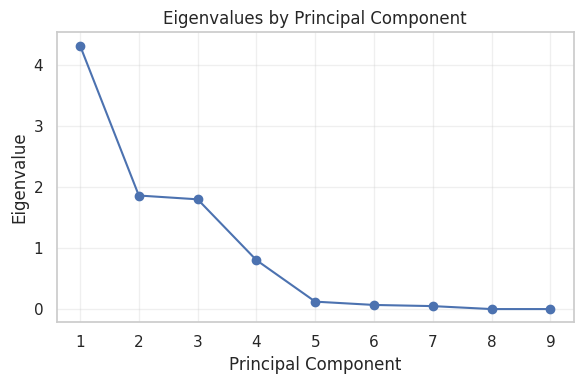

In [11]:
# ---- Eigenvalues vs Principal Component ----

plt.figure(figsize=(6, 4))
plt.plot(pc_indices, eigenvalues, marker="o")
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("Eigenvalues by Principal Component")
plt.xticks(pc_indices)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


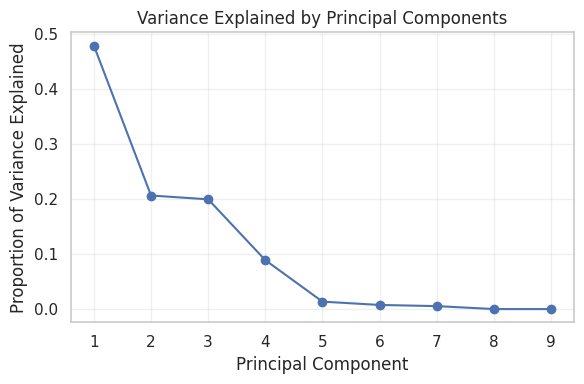

,PC,Eigenvalue,Prop_Var,Cum_Prop_Var,Prop_Var_%,Cum_Prop_Var_%
0,1,4.323887,0.478949,0.478949,47.894909,47.894909
1,2,1.862899,0.206350,0.685299,20.634996,68.529905
2,3,1.800570,0.199446,0.884745,19.944591,88.474495
3,4,0.802492,0.088891,0.973636,8.889062,97.363557
4,5,0.121834,0.013495,0.987131,1.349528,98.713085


In [13]:
# ---- Proportion of variance explained by each PC ----

plt.figure(figsize=(6, 4))
plt.plot(pc_indices, explained_var, marker="o")
plt.xlabel("Principal Component")
plt.ylabel("Proportion of Variance Explained")
plt.title("Variance Explained by Principal Components")
plt.xticks(pc_indices)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
variance_table.head()

In [23]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i}" for i in range(1, len(pca_features) + 1)],
    index=pca_features,
)

# Inspect the first few components
loadings.iloc[:, :4]


,PC1,PC2,PC3,PC4
minutes_played_total,0.2794,-0.1539,0.5296,-0.3061
matches_played,0.2785,-0.0645,0.5670,-0.1437
xThreat_total,0.4729,-0.0658,-0.0525,-0.0373
xThreat_pass_total,0.4406,-0.2667,-0.0679,0.0120
xThreat_carry_total,0.2466,0.6075,0.0320,-0.1656
xg_total,0.1020,0.1898,0.3718,0.8933
xThreat_per90,0.4177,0.0326,-0.3502,0.1071
xThreat_pass_per90,0.3851,-0.2389,-0.3451,0.1731
xThreat_carry_per90,0.1805,0.6584,-0.0981,-0.1317


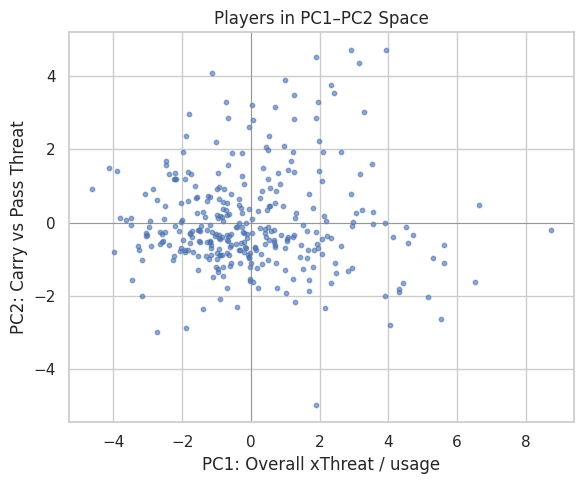

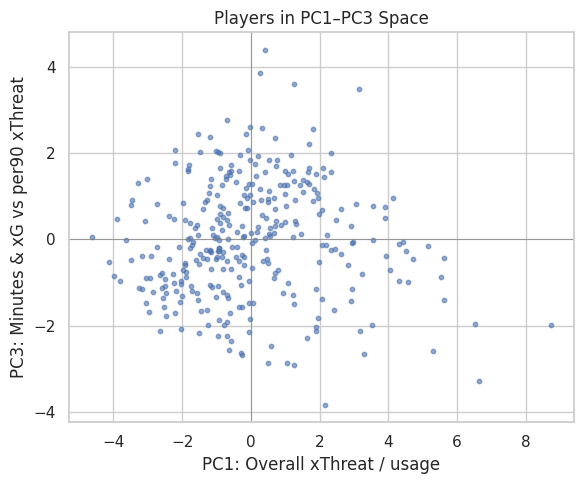

In [24]:
# Build a scores DF with PCs
pc_scores = pd.DataFrame(
    X_pca[:, :4],  # first 4 PCs
    columns=[f"PC{i}" for i in range(1, 5)]
)

pca_scores = pd.concat([pca_df.reset_index(drop=True), pc_scores], axis=1)

# Basic PC1 vs PC2 scatter
plt.figure(figsize=(6, 5))
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], alpha=0.6, s=10)
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.xlabel("PC1: Overall xThreat / usage")
plt.ylabel("PC2: Carry vs Pass Threat")
plt.title("Players in PC1–PC2 Space")
plt.tight_layout()
plt.show()

# PC1 vs PC3 scatter
plt.figure(figsize=(6, 5))
plt.scatter(pca_scores["PC1"], pca_scores["PC3"], alpha=0.6, s=10)
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.xlabel("PC1: Overall xThreat / usage")
plt.ylabel("PC3: Minutes & xG vs per90 xThreat")
plt.title("Players in PC1–PC3 Space")
plt.tight_layout()
plt.show()


In [26]:
def show_extreme_players(df, pc_name, k=10):
    cols = ["player_name", "team_name", pc_name]
    print(f"\nTop {k} on {pc_name}")
    display(df[cols].sort_values(pc_name, ascending=False).head(k))

    print(f"\nBottom {k} on {pc_name}")
    display(df[cols].sort_values(pc_name, ascending=True).head(k))

for pc in ["PC1", "PC2", "PC3", "PC4"]:
    show_extreme_players(pca_scores, pc)



Top 10 on PC1


,player_name,team_name,PC1
52,Marc Albrighton,Leicester City,8.7380
20,Kevin De Bruyne,Manchester City,6.6433
101,Dimitri Payet,West Ham United,6.5337
174,Steven Davis,Southampton,5.6212
95,Francesc Fàbregas i Soler,Chelsea,5.6082
157,Danny Drinkwater,Leicester City,5.5442
129,Yannick Bolasie Yala,Crystal Palace,5.3134
103,Mesut Özil,Arsenal,5.1633
92,Willian Borges da Silva,Chelsea,4.7212
288,Jason Puncheon,Crystal Palace,4.5814



Bottom 10 on PC1


,player_name,team_name,PC1
39,Benik Afobe,AFC Bournemouth,-4.6219
80,Martin Kelly,Crystal Palace,-4.1358
7,Pablo Javier Zabaleta Girod,Manchester City,-3.9804
303,Duncan Watmore,Sunderland,-3.8969
254,James Grant Chester,West Bromwich Albion,-3.8058
224,Valon Behrami,Watford,-3.6339
17,Heung-Min Son,Tottenham Hotspur,-3.5001
16,Jamaal Lascelles,Newcastle United,-3.4850
309,Arouna Koné,Everton,-3.4670
1,Memphis Depay,Manchester United,-3.2926



Top 10 on PC2


...

,player_name,team_name,PC3
269,Santiago Cazorla González,Arsenal,-3.8301
20,Kevin De Bruyne,Manchester City,-3.2793
304,Matt Jarvis,Norwich City,-2.9152
9,Jonjo Shelvey,Swansea City,-2.8749
322,Adam Johnson,Sunderland,-2.8604
270,Abdul Rahman Baba,Chelsea,-2.6790
168,Gerard Deulofeu Lázaro,Everton,-2.6534
10,Jonjo Shelvey,Newcastle United,-2.6436
129,Yannick Bolasie Yala,Crystal Palace,-2.5993
130,Rhu-endly Martina,Southampton,-2.5561



Top 10 on PC4


,player_name,team_name,PC4
260,Harry Kane,Tottenham Hotspur,4.2963
263,Jamie Vardy,Leicester City,3.5830
42,Romelu Lukaku Menama,Everton,3.2409
31,Sergio Leonel Agüero del Castillo,Manchester City,3.1190
105,Philippe Coutinho Correia,Liverpool,2.7752
197,Aleksandar Mitrović,Newcastle United,2.5005
172,Riyad Mahrez,Leicester City,2.3032
221,Odion Jude Ighalo,Watford,2.2317
138,Olivier Giroud,Arsenal,2.1708
61,Jermain Defoe,Sunderland,2.1229



Bottom 10 on PC4


,player_name,team_name,PC4
108,Héctor Bellerín Moruno,Arsenal,-1.6759
142,Simon Francis,AFC Bournemouth,-1.5632
216,Pape N''Diaye Souaré,Crystal Palace,-1.5188
106,Wilfried Zaha,Crystal Palace,-1.5184
191,Allan Romeo Nyom,Watford,-1.4781
114,Heurelho da Silva Gomes,Watford,-1.4406
26,Hugo Lloris,Tottenham Hotspur,-1.4213
253,Neil Taylor,Swansea City,-1.3803
33,Łukasz Fabiański,Swansea City,-1.3514
44,Joe Hart,Manchester City,-1.3422


### PCA Interpretation Reference

#### **PC1 – Overall xThreat Usage (especially passing)**
PC1 captures how involved a player is in creating danger, especially through passing actions.

- **High PC1 scores:**  
  Players who generate a lot of xThreat and xThreat_pass, both in total and per 90. These are high-usage attackers heavily involved in buildup and creative play.
- **Low PC1 scores:**  
  Players with low overall xThreat output and limited involvement in dangerous passing sequences.

---

#### **PC2 – Carry-heavy vs Pass-heavy Threat**
PC2 distinguishes players who generate threat primarily by carrying the ball versus those who create threat through passing.

- **High PC2 scores:**  
  Strong ball carriers who produce xThreat via dribbles and progressive carries.
- **Low PC2 scores:**  
  Pass-first creators who rely more on distribution and chance creation through passing rather than carrying.

---

#### **PC3 – Minutes & xG Volume vs per-90 Creation Efficiency**
PC3 reflects a contrast between total attacking volume and per-90 efficiency.

- **High PC3 scores:**  
  Players with large minute totals, many appearances, and high xG volume. These are consistent starters or workhorse attackers.
- **Low PC3 scores:**  
  Players who excel on a per-90 basis (high xThreat_per90 and xThreat_pass_per90) but may not accumulate large totals of minutes or xG.

---

#### **PC4 – Isolated Finishing Volume (xG Axis)**
PC4 isolates finishing output, specifically high xG totals.

- **High PC4 scores:**  
  High-volume finishers who accumulate large xG totals regardless of other threat metrics.
- **Low PC4 scores:**  
  Players whose contributions lean more toward creation or carrying rather than pure shot volume or finishing.
